# 01 — Exploratory Data Analysis

Egyptian sentiment data (ASTD + ArSarcasm-v2 Egyptian subset) after `src.data.unify` and `src.data.split`.

Arabic text is shown in tables, not plots (matplotlib can't shape Arabic script).

In [1]:
import json, os, re
from collections import Counter
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.preprocess import preprocess, tokenize

pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")
PLOTS = Path("results/plots"); PLOTS.mkdir(parents=True, exist_ok=True)
LABEL_ORDER = ["negative", "neutral", "positive"]

all_df = pd.read_csv("data/processed/all.csv")
splits = {s: pd.read_csv(f"data/processed/{s}.csv") for s in ["train", "val", "test"]}
stats = json.loads(Path("data/processed/split_stats.json").read_text())
print(f"all: {len(all_df):,} rows | " + " | ".join(f"{k}: {len(v):,}" for k, v in splits.items()))

all: 11,408 rows | train: 9,126 | val: 1,141 | test: 1,141


## 1. Label distribution

All splits keep the natural distribution. Imbalance is handled with class-weighted losses. Capping neutral in train was tried for M1 and cost ~3–4 macro-F1 points, so it was dropped.

In [2]:
counts = pd.DataFrame([{"split": s, "label": l, "n": n} for s, c in stats.items() for l, n in c.items()])
table = counts.pivot_table(index="split", columns="label", values="n").reindex(index=["train", "val", "test"], columns=LABEL_ORDER)
table["total"] = table.sum(axis=1)
display(table.astype(int))
display((table[LABEL_ORDER].div(table["total"], axis=0) * 100).round(1).rename(columns=lambda c: c + " %"))

label,negative,neutral,positive,total
split,,,,
train,2001,6278,847,9126
val,251,785,105,1141
test,249,786,106,1141


label,negative %,neutral %,positive %
split,,,
train,21.9,68.8,9.3
val,22.0,68.8,9.2
test,21.8,68.9,9.3


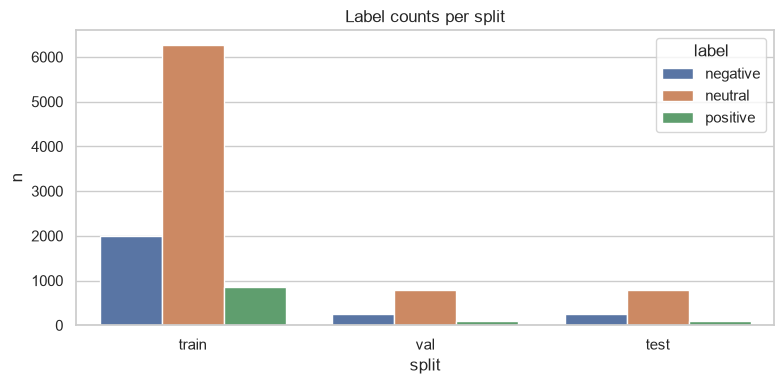

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=counts, x="split", y="n", hue="label", hue_order=LABEL_ORDER, order=["train", "val", "test"], ax=ax)
ax.set_title("Label counts per split")
fig.tight_layout(); fig.savefig(PLOTS / "eda_label_counts.png", dpi=150)

## 2. Sources

`arsarcasm|astd` = the same tweet appeared in both datasets with the same label (kept once). Conflicting duplicates were dropped in `unify`.

In [4]:
display(pd.crosstab(all_df["source"], all_df["label"], margins=True)[LABEL_ORDER + ["All"]])

label,negative,neutral,positive,All
source,,,,
arsarcasm,896,721,306,1923
arsarcasm|astd,475,68,156,699
astd,1130,7060,596,8786
All,2501,7849,1058,11408


## 3. Text length (tokens after full preprocessing)

Used to choose `max_len` for the LSTM (planned 64).

In [5]:
all_df["clean"] = all_df["text"].map(preprocess)
all_df["n_tokens"] = all_df["clean"].map(lambda t: len(tokenize(t)))
display(all_df.groupby("label")["n_tokens"].describe(percentiles=[.5, .9, .95, .99]).round(1))
print("share of texts longer than 64 tokens:", round((all_df.n_tokens > 64).mean() * 100, 2), "%")

,count,mean,std,min,50%,90%,95%,99%,max
label,,,,,,,,,
negative,2501.0,18.7,8.1,1.0,19.0,26.0,29.0,50.0,65.0
neutral,7849.0,15.6,6.5,1.0,16.0,24.0,26.0,29.0,68.0
positive,1058.0,15.4,7.5,1.0,15.5,25.0,27.0,31.0,52.0


share of texts longer than 64 tokens: 0.03 %


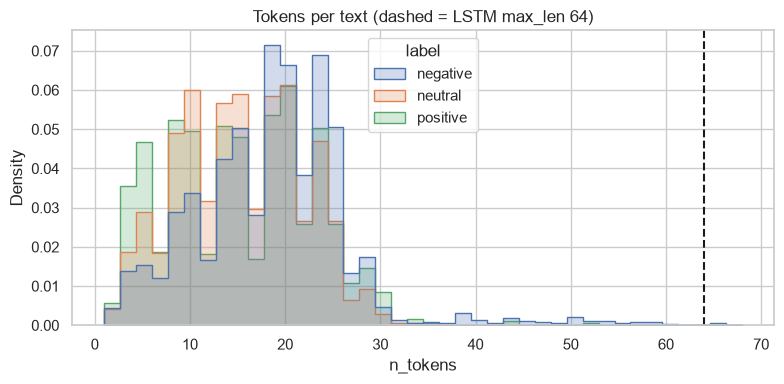

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=all_df, x="n_tokens", hue="label", hue_order=LABEL_ORDER, bins=40, element="step", stat="density", common_norm=False, ax=ax)
ax.axvline(64, ls="--", c="k"); ax.set_title("Tokens per text (dashed = LSTM max_len 64)")
fig.tight_layout(); fig.savefig(PLOTS / "eda_lengths.png", dpi=150)

## 4. Vocabulary

Tokens in val/test that never appear in train are invisible to the embedding models (M2, M3) — a first hint at how hard dialect generalization is.

In [7]:
tok = {s: [t for x in df["text"] for t in tokenize(preprocess(x))] for s, df in splits.items()}
train_vocab = Counter(tok["train"])
print(f"train vocab: {len(train_vocab):,} types | {sum(train_vocab.values()):,} tokens")
print(f"types seen >= 2 times: {sum(1 for c in train_vocab.values() if c >= 2):,}")
for s in ["val", "test"]:
    oov = sum(1 for t in tok[s] if t not in train_vocab) / len(tok[s])
    print(f"{s} token OOV rate vs train: {oov:.1%}")

train vocab: 33,156 types | 148,398 tokens
types seen >= 2 times: 12,165
val token OOV rate vs train: 14.9%
test token OOV rate vs train: 15.3%


## 5. Most distinctive tokens per class

Ranked by smoothed log-odds of a token appearing in that class vs the others (train split, min count 5).

In [8]:
import math
train = splits["train"].assign(toks=splits["train"]["text"].map(lambda x: tokenize(preprocess(x))))
by_label = {l: Counter(t for ts in train.loc[train.label == l, "toks"] for t in ts) for l in LABEL_ORDER}
total = Counter(); [total.update(c) for c in by_label.values()]
rows = {}
for l, c in by_label.items():
    rest = total - c
    n_c, n_r = sum(c.values()), sum(rest.values())
    scores = {t: math.log((c[t] + 1) / (n_c + len(total))) - math.log((rest[t] + 1) / (n_r + len(total)))
              for t in c if total[t] >= 5}
    rows[l] = [t for t, _ in sorted(scores.items(), key=lambda kv: -kv[1])[:20]]
display(pd.DataFrame(rows))

,negative,neutral,positive
0,عار,الوفد,❤
1,فاشل,بعنوان,💕
2,مسخره,🌼,الرائع
3,الوسخه,نيوز,برافو
4,كلب,حمزاوي,فخور
5,الكلب,ذات,☆
6,ناقص,الاحد,تركع
7,الناتو,دبي,🎶
8,بوتن,اوكرانيا,هيه
9,اسوا,البوابه,♥


## 6. Emojis per class

In [9]:
emoji_re = re.compile(r"[\U0001F300-\U0001FAFF\u2600-\u27BF]")
train["emojis"] = train["text"].map(emoji_re.findall)
print("train texts with >=1 emoji:", f"{(train.emojis.str.len() > 0).mean():.1%}")
display(pd.DataFrame({l: [f"{e} ({n})" for e, n in Counter(e for es in train.loc[train.label == l, "emojis"] for e in es).most_common(10)]
                      for l in LABEL_ORDER}))

train texts with >=1 emoji: 4.6%


,negative,neutral,positive
0,😂 (100),😂 (107),😂 (159)
1,💔 (13),🌼 (24),❤ (34)
2,😁 (7),😍 (18),😍 (33)
3,😭 (7),♡ (17),☆ (24)
4,👌 (7),⚪ (16),♡ (12)
5,🏻 (5),💃 (12),😭 (8)
6,😅 (4),❤ (11),♥ (7)
7,😔 (4),😝 (10),👏 (7)
8,😎 (4),✋ (8),💙 (6)
9,🔫 (4),🏻 (8),👌 (6)


## 7. Random samples per class

In [10]:
for l in LABEL_ORDER:
    print(f"--- {l} ---")
    for t in splits["train"].loc[splits["train"].label == l, "text"].sample(5, random_state=0):
        print("  ", t)

--- negative ---
   نفسي فيه و تفوو عليه ! #فيفي_عبده =))
   الدعم الصهيوني للإخوان أهدافه منع حماس من الهجوم على اسرائيل صراع سني شيعي يمزق المنطقةضمان تخلف مصر الدائم تحت حكم الاخوان الفاشي الفاشل
   بلطجة الإخوان والإعتداء على الإعلاميين بمحيط اكاديمية الشرطة #السادة_المحترمون
   محمد بديع: أطلب من أبي محمد حسني مبارك أن يرفع الظلم على المسجونين #مصر #فلسطين #تونس #قطر #سوريا #الإمارات #لبنان
   ويندوز 10 بيعمل تقريبا كل حاجه بمزاجه والموضوع مخيف
--- neutral ---
   ماشي يا كبير
   "_: #عشان_خاطر_ماسر هات البتاعه دي " #انتخبوا_العرص
   تعلم التوازن فى الحياة أربع دقائق
   فريق عمل يشارك قوات الأمن في اقتحام دلجا …
   اشمعنى انتا تتويت يجيلك 1000 فولو وانا اتويت يتعملى ان فولو - ربنا مايرضاش بظلم #جمعية_الاقل_من1000_فلورز
--- positive ---
   المجلس الانتقالي الليبي يكرم قناة ''اون تي في'' الفضائية المصرية، باعتبارها أفضل قناة فى تغطية أحداث ليبيا #25 #
   لبيك اللهم لبيك لبيك لا شريك لك لبيك إن الحمد و النعمة لك و الملك لا شريك لك
   " مسيرة جت من #التحرير في #طلعت_حرب وصلوا ميدان طلع

## Takeaways

1. **Class balance.** All splits are ~22/69/9 (neg/neu/pos); class-weighted losses handle the imbalance (capping neutral was tried for M1 and hurt). Positive is the scarcest class (~850 train, ~105 test) → expect the weakest per-class F1 there; macro-F1 is the headline metric because accuracy is inflated by neutral.
2. **Length.** Texts are short (median 15–19 tokens, 99th pct ≤ 50). `max_len=64` for the LSTM truncates ~0.03% of texts. 128 subwords is ample for the transformers.
3. **Vocabulary / OOV.** ~20% of val/test tokens are unseen in train, so word-level models (M2, M3) lean heavily on pretrained AraVec vectors; char n-grams in M1 should help with spelling variation.
4. **Topic bias.** The data is mostly 2013–2015 Egyptian political/news tweets. Distinctive tokens include politics and news words for neutral/negative and a TV personality's name for positive, which are spurious cues. Our custom test set (restaurants, products, football, everyday speech) is therefore *out-of-domain* as well as dialect-focused; interpret drops with that in mind.
5. **Not purely Egyptian.** Many "Egyptian" tweets are news-style MSA. The dialect signal in training is weaker than the source label suggests, which is part of what the MSA-vs-dialect comparison will reveal.
6. **Emojis.** Only ~6% of tweets have one, and 😂 is the top emoji in *both* positive and negative (sarcasm/mockery), so emojis alone are not reliable sentiment cues.
7. **Label noise.** Random samples include news headlines labeled positive, and 330 texts had conflicting labels between ASTD and ArSarcasm. Expect a noise ceiling on in-domain scores.
